# Étape 7 — Prédiction d’une image

**Termes techniques :** RGB, redimensionnement, normalisation, batch, Softmax, argmax, probabilité

## Charger le modèle et les classes

In [5]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display

PROJECT_DIR = Path.cwd()
while PROJECT_DIR != PROJECT_DIR.parent and not (PROJECT_DIR / "models" / "cnn_scenevision.keras").is_file():
    PROJECT_DIR = PROJECT_DIR.parent
TRAIN_CSV = PROJECT_DIR / "data" / "split" / "train.csv"
SELECTED_MODEL = PROJECT_DIR / "models" / "cnn_scenevision_selected.keras"
BASE_MODEL = PROJECT_DIR / "models" / "cnn_scenevision.keras"
MODEL_PATH = SELECTED_MODEL if SELECTED_MODEL.exists() else BASE_MODEL
IMG_SIZE = (150, 150)
class_names = sorted(pd.read_csv(TRAIN_CSV)["label"].unique())
model = tf.keras.models.load_model(MODEL_PATH)
print("Modèle chargé :", MODEL_PATH.name)
print("Classes :", class_names)

Modèle chargé : cnn_scenevision_selected.keras
Classes : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


## Fonction predict_image

In [6]:
def predict_image(image_path):
    image = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE, color_mode="rgb")
    image_array = tf.keras.utils.img_to_array(image) / 255.0
    probabilities = model.predict(np.expand_dims(image_array, axis=0), verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    print(f"Classe prédite : {class_names[predicted_index]} ({probabilities[predicted_index]:.2%})")
    scores = pd.DataFrame({"classe": class_names, "probabilité": probabilities})
    return scores.sort_values("probabilité", ascending=False).reset_index(drop=True)

## Tester sur trois images non étiquetées

Image : 10004.jpg


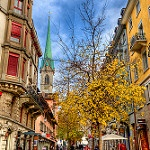

Classe prédite : buildings (39.51%)


,classe,probabilité
0,buildings,0.395
1,forest,0.380
2,street,0.220
3,glacier,0.004
4,sea,0.001
5,mountain,0.000


Image : 10005.jpg


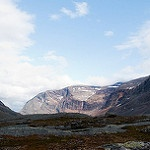

Classe prédite : mountain (80.59%)


,classe,probabilité
0,mountain,0.806
1,sea,0.137
2,glacier,0.053
3,forest,0.002
4,buildings,0.001
5,street,0.000


Image : 10012.jpg


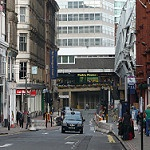

Classe prédite : street (95.73%)


,classe,probabilité
0,street,0.957
1,buildings,0.043
2,forest,0.000
3,glacier,0.000
4,sea,0.000
5,mountain,0.000


In [7]:
UNLABELED_DIR = PROJECT_DIR / "data" / "raw" / "seg_pred"
sample_paths = sorted(UNLABELED_DIR.glob("*.jpg"))[:3]
assert len(sample_paths) == 3, "Trois images JPG sont nécessaires pour cet exemple."

for image_path in sample_paths:
    print("Image :", image_path.name)
    display(tf.keras.utils.load_img(image_path, target_size=IMG_SIZE))
    display(predict_image(image_path).round(3))

## Tester une image personnelle

In [8]:
# Remplacez ce chemin par le chemin de votre image.
IMAGE_PATH = sample_paths[0]
display(predict_image(IMAGE_PATH).round(3))

Classe prédite : buildings (39.51%)


,classe,probabilité
0,buildings,0.395
1,forest,0.380
2,street,0.220
3,glacier,0.004
4,sea,0.001
5,mountain,0.000
